# MT response and a measured QC decision

**Level 1 — Foundations**  
**Prerequisites:** Python basics; 35 min.

## Objectives

Trace the evidence from source contract to result. State units and assumptions, reproduce the calculation, and identify which inference the evidence cannot support.

## Setup

Uses repository modules and committed records through a discovered root; it downloads and mutates nothing. Install exact pins: `pip install numpy==2.2.6 matplotlib==3.10.8` `scipy==1.15.2` is required by the MT forward operator.

## Data

Measured QC-only record plus a separate seeded synthetic calibration artifact; never merge these evidence classes.

## Method

Clear Lake `cl061` is measured field data with 42 frequencies and unknown subsurface truth. Its committed screen fails the necessary 1D tensor-consistency test; it remains **QC-only** and must not be fit with the layered inverse. This lesson applies the implemented `mt_field_qc.tensor_gate` and `phase_tensor_diagnostic` directly to the committed tensor and marginal uncertainties. It also inspects the supplied tipper, which is ancillary evidence and is never an input to the 1D solver.

The EDI rotation is preserved in its supplied frame (`rotation_action: none`); no covariance-free re-rotation is attempted. The module checks that its geometric distance to an ideal 1D tensor is invariant under a quarter-turn, a diagnostic property rather than a reprocessing of this station. Tipper variance is explicitly uninterpreted in the source receipt, so plot component magnitude and missing frequencies only; do not form normalized tipper residuals or error bars from it.

With `exp(+iωt)`, `Z=E/H` is in Ω, apparent resistivity `ρₐ=|Z|²/(μ₀ω)` in Ω·m, phase in degrees and period `T=1/f` in seconds. The screen is a necessary consistency null, not proof of dimensionality. A failure cannot be repaired by tuning a 1D fit.

### Diagnostic 1

Inspect the committed case record and provenance.

In [1]:
# Apply implemented product QC diagnostics to the measured tensor; do not fit cl061.
import json, sys
from pathlib import Path
import numpy as np
from importlib.metadata import version
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
sys.path.insert(0,str(root/"data-pipeline"))
from mt_field_qc import tensor_gate, phase_tensor_diagnostic
case=json.loads((root/"data/derived/v2/edi/clear-lake-cl061-screen.json").read_text(encoding="utf-8"))
f=np.asarray(case["frequencies_hz"],float); period=1/f
z=np.asarray(case["tensor"]["real"])+1j*np.asarray(case["tensor"]["imag"])
sigma=np.asarray(case["tensor"]["sigma"],float)
gate=tensor_gate(z,sigma**2)  # Receipt stores marginal SD; the QC function accepts variance.
phase_qc=phase_tensor_diagnostic(z); tip=case["metadata"]["tipper"]
print("Runtime:",{name:version(name) for name in ("numpy","matplotlib","scipy")})
print("Measured source:",case["id"],case["source_kind"],"N=",len(f),"truth=",case["truth"])
print("Eligibility:",case["one_d_inversion_eligible"],"stored screen:",case["compatibility"]["passes_screen"],"recomputed:",gate["passes"])
print("QC scores:",list(gate["per_period_normalized"]),"limit:",gate["threshold"])
print("Quarter-turn geometric invariance max error:",gate["quarter_turn_invariance_max_abs_error"])
print("Usable phase-tensor periods:",phase_qc["usable_periods"],"median scalar departure:",phase_qc["median_scalar_departure"])
print("Tipper present:",tip["present"],"used by 1D inverse:",tip["used_in_1d_inversion"],"variance:",tip["raw_variance_convention"])

Runtime: {'numpy': '2.2.6', 'matplotlib': '3.10.8', 'scipy': '1.15.2'}
Measured source: cl061 measured EDI transfer functions N= 42 truth= None
Eligibility: False stored screen: False recomputed: False
QC scores: ['xx', 'yy', 'antisymmetry'] limit: 3.0
Quarter-turn geometric invariance max error: 1.1102230246251565e-16
Usable phase-tensor periods: 42 median scalar departure: 0.257651139958079
Tipper present: True used by 1D inverse: False variance: uninterpreted EDI native variance


### Diagnostic 2 — Recompute tensor QC and inspect ancillary tipper

The upper-right panel shows the three noise-normalized necessary 1D checks by period. The lower-right overlay shows phase-tensor scalar departure and raw tipper magnitude; these are QC clues, not a 1D inversion target. Missing tipper periods remain missing.

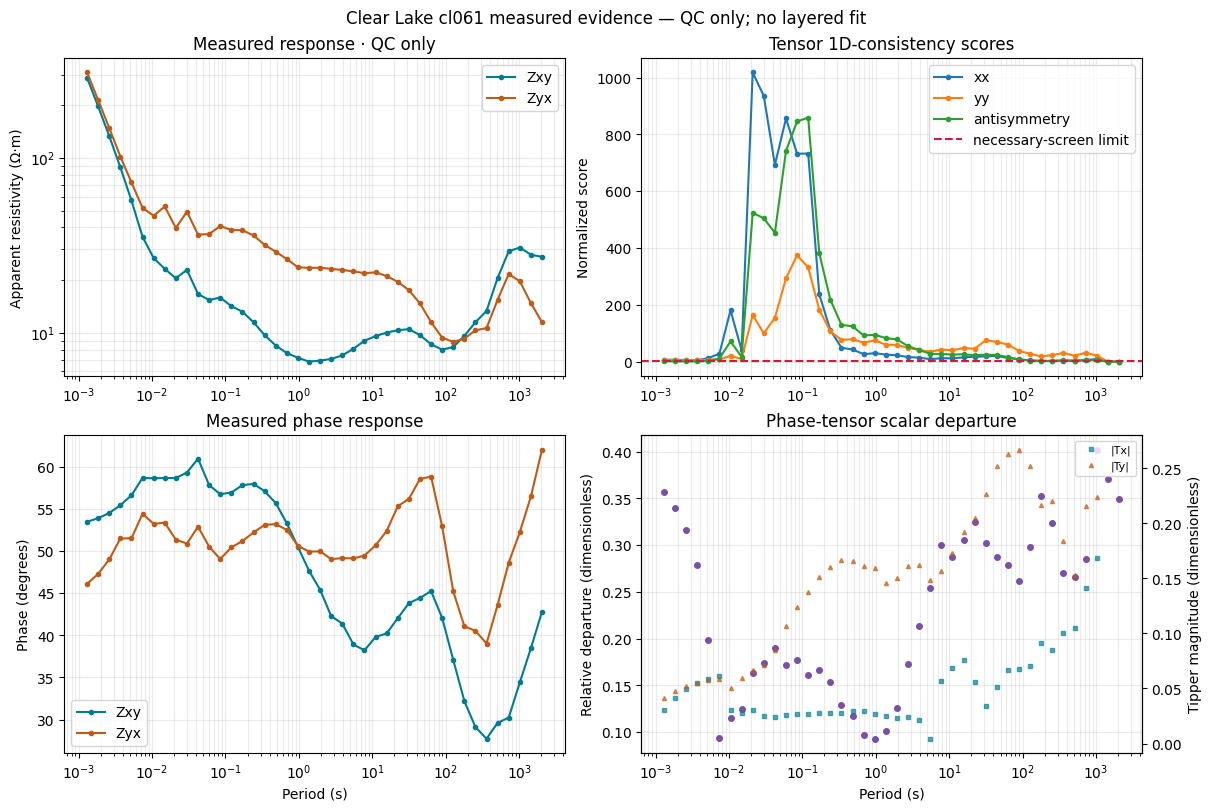

Tipper missing frequencies (Hz): [0.0004882812, 0.0006915263]
Tipper variance convention is uninterpreted; no tipper uncertainty bars are shown.


In [2]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
for name,color in (("xy","#007c91"),("yx","#bf5b17")):
 q=case["observed"][name]; ax[0,0].loglog(period,q["apparent"],".-",label="Z"+name,color=color); ax[1,0].semilogx(period,q["phase"],".-",label="Z"+name,color=color)
ax[0,0].set_ylabel("Apparent resistivity (Ω·m)"); ax[1,0].set_ylabel("Phase (degrees)"); ax[1,0].set_xlabel("Period (s)")
for a in (ax[0,0],ax[1,0]): a.grid(True,which="both",alpha=.25); a.legend()
ax[0,0].set_title("Measured response · QC only")
for key,score in gate["per_period_normalized"].items(): ax[0,1].semilogx(period,score,".-",label=key)
ax[0,1].axhline(gate["threshold"],color="crimson",ls="--",label="necessary-screen limit"); ax[0,1].set_title("Tensor 1D-consistency scores"); ax[0,1].set_ylabel("Normalized score"); ax[0,1].legend(); ax[0,1].grid(True,which="both",alpha=.25)
pt=phase_qc["per_period"]; pt_period=np.asarray([period[row["source_index"]] for row in pt]); pt_depart=np.asarray([row["scalar_departure"] for row in pt])
ax[1,0].set_title("Measured phase response"); ax[1,1].semilogx(pt_period,pt_depart,"o",ms=4,color="#7651a8"); ax[1,1].set_title("Phase-tensor scalar departure"); ax[1,1].set_ylabel("Relative departure (dimensionless)"); ax[1,1].set_xlabel("Period (s)"); ax[1,1].grid(True,which="both",alpha=.25)
# Tipper variance is uninterpreted: plot raw component magnitudes only; NaNs retain missing values.
tf=np.asarray(tip["components"]["X"]["real"],dtype=float)+1j*np.asarray(tip["components"]["X"]["imag"],dtype=float); ty=np.asarray(tip["components"]["Y"]["real"],dtype=float)+1j*np.asarray(tip["components"]["Y"]["imag"],dtype=float)
ax2=ax[1,1].twinx(); ax2.semilogx(period,np.abs(tf),"s",ms=3,color="#007c91",alpha=.65,label="|Tx|"); ax2.semilogx(period,np.abs(ty),"^",ms=3,color="#bf5b17",alpha=.65,label="|Ty|"); ax2.set_ylabel("Tipper magnitude (dimensionless)")
h,l=ax[1,1].get_legend_handles_labels(); h2,l2=ax2.get_legend_handles_labels(); ax2.legend(h+h2,l+l2,fontsize=8,loc="best")
fig.suptitle("Clear Lake cl061 measured evidence — QC only; no layered fit"); plt.show()
print("Tipper missing frequencies (Hz):",tip["missing_frequency_hz"])
print("Tipper variance convention is uninterpreted; no tipper uncertainty bars are shown.")

## Results

The dataset remains QC-only because the 1D eligibility screen fails; its tensor and tipper diagnostics are not a layered-earth inversion. Missing tipper periods remain missing.

## Summary

Use the QC decision only to state whether a 1D layered inverse is eligible. `cl061` fails the necessary screen and remains excluded from 1D fitting.

## References

- [MTpy v2](https://github.com/MTgeophysics/mtpy-v2)
- [USGS Clear Lake magnetotelluric data](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california)
